# Author Independence

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Survey

The existing `survey.xlsx` contains two survey inputs: sheet `u` records independence weights, and sheet `hop` records collaboration-distance choices. Read them separately below. The final survey cell draws the response-count and weight-distribution panels and saves `assets/survey.pdf`; jitter uses seed 42.


### Read weight responses

Load sheet `u`; index `i` identifies respondents locally. No new data file is written.


In [2]:
u_df = pd.read_excel('survey.xlsx', 'u', index_col='i')

### Read collaboration-distance responses

Load the `hop` response-count sheet for the left panel of the survey figure.


In [3]:
dist_df = pd.read_excel('survey.xlsx', 'hop')

### Output the survey figure

Draw both survey panels and save `assets/survey.pdf`. Rerunning this cell changes the figure only; the survey input is not overwritten.


C:\Users\minam\AppData\Local\Temp\ipykernel_36728\2140935922.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(distdf['x'], rotation=45, ha="right")


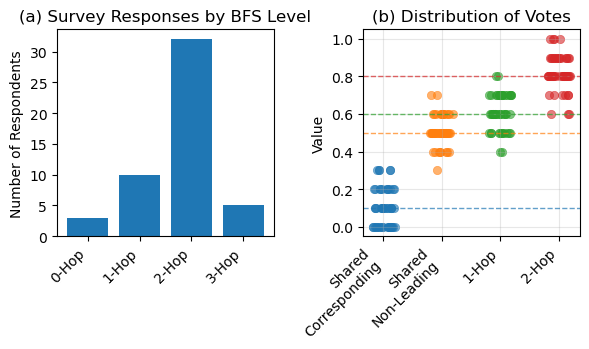

In [4]:
def plot_survey(distdf, udf, size=(6, 3.6), save_path=None):
    # Create figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=size)
    plt.subplots_adjust(wspace=0.3, hspace=0)

    distdf['x'] = distdf['hop'].astype('str') + '-Hop'
    ax1.bar(distdf['x'], distdf['count'])
    ax1.set_title('(a) Survey Responses by BFS Level')
    ax1.set_ylabel('Number of Respondents')
    ax1.set_xticklabels(distdf['x'], rotation=45, ha="right")


    # ========== LEFT: SCATTER PLOT ==========
    x_labels = ['Shared\nCorresponding', 'Shared\nNon-Leading','1-Hop', '2-Hop']
    udf[x_labels[0]] = udf['corresponding author']
    udf[x_labels[1]] = udf['other']
    udf[x_labels[2]] = udf['1-hop']
    udf[x_labels[3]] = udf['2-hop']
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    df = udf[x_labels]
    rng = np.random.default_rng(42)
    for i, (col, color) in enumerate(zip(df.columns, colors)):
        # 增加抖动宽度
        jitter = rng.uniform(-0.2, 0.2, size=len(df))
        x_positions = np.full(len(df), i) + jitter
        
        # 画散点
        ax2.scatter(x_positions, df[col], alpha=0.6, color=color, linewidth=0.5, label=col)
        
        # 添加均值线
        mean_val = round(df[col].mean()*10)/10
        ax2.axhline(y=mean_val, color=color, linestyle='--', alpha=0.7, linewidth=1)


    ax2.set_ylabel('Value')
    ax2.set_xticks(range(len(x_labels)))
    ax2.set_xticklabels(x_labels, rotation=45, ha="right")
    ax2.set_title('(b) Distribution of Votes')
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    if save_path:
        plt.savefig(
            save_path,
            bbox_inches="tight",
        )
    plt.show()
# plot_survey(df, size=(7.2, 4.5), save_path="assets/survey.pdf")
plot_survey(dist_df, u_df, save_path="assets/survey.pdf")

## Database cohort and beta sensitivity

This analysis reads citations to the fixed 400 seed papers directly from PostgreSQL. Queries are read-only, no LLM calls are made, and no intermediate XLSX is created. Missing author-independence scores are excluded, not replaced by 1. The saved author-graph scores are used without recalculation.

Run the steps below in order, normally from `src/`. Statistics, the two figures, and file export have separate cells. After data are loaded, changing a plotting parameter only requires rerunning the plotting helper and figure cells, not querying the database again. Figure legends report the actual selected-beta statistics from Step 7, not fixed acceptance thresholds. Rerun the figure cells after updating the statistics.


### 1. Configure inputs, parameters, and the database reader

Define paths and the read-only SQLAlchemy query; this cell does not query the database. The existing seed spreadsheet is the only seed input. Use alpha=0.2, the existing final abstract-only multiplier 0.8, and beta values from 0 to 1 at increments of 0.02. Beta=0.5 is the current design reference. The figures mark the selected beta and its measured drop and Spearman from Step 7; they do not display fixed acceptance thresholds.


In [5]:
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import os
import sys

from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, select
from sqlalchemy.engine import make_url
from sqlalchemy.orm import aliased
from sqlalchemy.pool import NullPool

SRC_DIR = Path.cwd().resolve()
if not (SRC_DIR / "postgres" / "model.py").is_file():
    SRC_DIR = SRC_DIR / "src"
if not (SRC_DIR / "postgres" / "model.py").is_file():
    raise RuntimeError("Run this notebook from src/ or the repository root.")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from postgres.model import Author, Citation, Paper, PaperAuthor

# Existing inputs only; no database extract is written to Excel.
SEED_FILE = SRC_DIR / "sample" / "seed_papers_final.xlsx"
OUTPUT_DIR = SRC_DIR / "sample" / "author_independence"
ASSET_DIR = SRC_DIR / "assets"
ALPHA = 0.2
CONTEXT_DISCOUNT = 0.8  # Existing final multiplier, not 0.95 * 0.8 again.
CONTEXT_ONLY = False  # True restricts the analysis to context-bearing pairs.
SELECTED_BETA = 0.5
BETAS = np.linspace(0, 1, 51)
RANDOM_STATE = 42
SAVE_RESULTS = True  # Aggregate curves/counts/metadata only; no citation IDs.


def load_seed_ids(path):
    seeds = pd.read_excel(path, usecols=["id"])
    values = pd.to_numeric(seeds["id"], errors="raise")
    if (values.isna().any() or values.le(0).any()
            or values.mod(1).ne(0).any() or values.duplicated().any()):
        raise ValueError("Seed IDs must be distinct positive integers.")
    if len(values) != 400:
        raise ValueError("Expected the fixed 400-seed input.")
    return values.astype("int64").tolist()


def read_author_citations(seed_ids):
    """Read citation and author inputs in one read-only database snapshot."""
    load_dotenv(SRC_DIR.parent / ".env", override=False)
    load_dotenv(SRC_DIR / ".env", override=False)
    if os.getenv("DATABASE_URL"):
        url = make_url(os.environ["DATABASE_URL"]).set(drivername="postgresql+psycopg")
    else:
        if not os.getenv("POSTGRES_USER") or not os.getenv("POSTGRES_DB"):
            raise RuntimeError("Set POSTGRES_USER and POSTGRES_DB, or DATABASE_URL.")
        url = URL.create(
            "postgresql+psycopg",
            username=os.environ["POSTGRES_USER"],
            password=os.getenv("POSTGRES_PASS") or os.getenv("POSTGRES_PASSWORD"),
            host=os.getenv("POSTGRES_HOST", "localhost"),
            port=int(os.getenv("POSTGRES_PORT", "5432")),
            database=os.environ["POSTGRES_DB"],
        )
    engine = create_engine(
        url, poolclass=NullPool, isolation_level="REPEATABLE READ",
        connect_args={
            "connect_timeout": 10,
            "options": "-c default_transaction_read_only=on "
                       "-c statement_timeout=120000 -c lock_timeout=5000",
        },
    )
    citing, cited = aliased(Paper), aliased(Paper)
    query = (
        select(
            Citation.citing_corpus_id, Citation.cited_corpus_id, Citation.contexts,
            Citation.cross_score, Citation.llm_score,
            Citation.abstract_cross_score, Citation.abstract_llm_score,
            Citation.author_independence,
            citing.abstract.label("citing_abstract"),
            cited.abstract.label("cited_abstract"),
        )
        .select_from(Citation)
        .outerjoin(citing, citing.corpus_id == Citation.citing_corpus_id)
        .outerjoin(cited, cited.corpus_id == Citation.cited_corpus_id)
        .where(Citation.cited_corpus_id.in_(seed_ids))
        .order_by(Citation.cited_corpus_id, Citation.citing_corpus_id)
    )
    try:
        with engine.connect() as connection, connection.begin():
            citation_result = connection.execute(query)
            citations = pd.DataFrame(
                citation_result.fetchall(), columns=list(citation_result.keys())
            )
            paper_ids = sorted(set(seed_ids) | set(citations["citing_corpus_id"]))
            author_query = (
                select(
                    PaperAuthor.paper_id, PaperAuthor.author_id,
                    PaperAuthor.author_order, Author.name.label("author_name"),
                )
                .outerjoin(Author, Author.author_id == PaperAuthor.author_id)
                .where(PaperAuthor.paper_id.in_(paper_ids))
                .order_by(PaperAuthor.paper_id, PaperAuthor.author_order)
            )
            author_result = connection.execute(author_query)
            authors = pd.DataFrame(
                author_result.fetchall(), columns=list(author_result.keys())
            )
    except Exception as error:
        # Do not expose the connection URL, password, or query parameters.
        raise RuntimeError(
            f"Read-only database query failed ({type(error).__name__}). "
            "Check the connection and schema locally."
        ) from None
    finally:
        engine.dispose()
    return citations, authors


### 2. Define eligibility and the unpenalized baseline

Context takes priority; use the citing abstract only when context is unavailable. Require a cited abstract and valid scores for the active branch. Both papers need nonempty author lists with valid IDs, names, and unique contiguous 0/1-based order, plus a recorded U in [0,1]. These checks establish database-observable coverage, not exhaustive author or historical collaboration data. Retain all U levels, including shared-author citations, to examine the penalty itself. This cell only defines functions.


In [6]:
def usable_text(value):
    return isinstance(value, str) and bool(value.strip())


def context_status(value):
    """Return (available, valid); malformed JSONB is not silently abstract-only."""
    if value is None:
        return False, True
    if isinstance(value, str):
        return usable_text(value), True
    if isinstance(value, dict):
        for key in ("text", "context", "sentence"):
            if key in value:
                return context_status(value[key])
        return False, False
    if isinstance(value, list):
        items = [context_status(item) for item in value]
        return any(available for available, _ in items), all(valid for _, valid in items)
    return False, False


def checked_unit_score(series):
    values = pd.to_numeric(series, errors="coerce")
    not_boolean = ~series.map(lambda x: isinstance(x, (bool, np.bool_)))
    return values.where(np.isfinite(values) & values.between(0, 1) & not_boolean)


def authors_ready(group):
    """Database-observable coverage, not proof of exhaustive author/history data."""
    ids = pd.to_numeric(group["author_id"], errors="coerce")
    order = pd.to_numeric(group["author_order"], errors="coerce")
    if (ids.isna().any() or ids.le(0).any() or ids.mod(1).ne(0).any()
            or ids.duplicated().any() or order.isna().any()
            or order.mod(1).ne(0).any() or order.duplicated().any()
            or not group["author_name"].map(usable_text).all()):
        return False
    first = int(order.min())
    return first in (0, 1) and sorted(order.astype(int)) == list(
        range(first, first + len(group))
    )


def prepare_author_cohort(citations, authors, seed_ids, alpha=0.2,
                          context_discount=0.8, context_only=False):
    if not 0 <= alpha <= 1 or not 0 < context_discount < 0.95:
        raise ValueError("Invalid alpha or final context discount.")
    d = citations.copy()
    if d.duplicated(["citing_corpus_id", "cited_corpus_id"]).any():
        raise ValueError("Duplicate citation pairs in database query.")
    ready_papers = {
        int(paper_id) for paper_id, group in authors.groupby("paper_id")
        if authors_ready(group)
    }
    statuses = d["contexts"].map(context_status)
    has_context = statuses.map(lambda x: x[0])
    valid_context = statuses.map(lambda x: x[1])
    has_cited = d["cited_abstract"].map(usable_text)
    has_citing = d["citing_abstract"].map(usable_text)
    d["branch"] = np.where(has_context, "context", "abstract")
    # Context always takes priority; missing context scores do not trigger fallback.
    cross = checked_unit_score(d["cross_score"]).where(
        has_context, checked_unit_score(d["abstract_cross_score"])
    )
    llm = checked_unit_score(d["llm_score"]).where(
        has_context, checked_unit_score(d["abstract_llm_score"])
    )
    d["cross"] = cross
    d["llm"] = llm
    d["U"] = checked_unit_score(d["author_independence"])
    weight = np.where(has_context, 1.0, context_discount)
    d["base"] = (alpha * cross + (1 - alpha) * llm) * weight

    coverage = [("Seed papers in fixed input", len(seed_ids)),
                ("Stored citation pairs to seeds", len(d))]
    retained = pd.Series(True, index=d.index)
    filters = [
        ("After cited-abstract requirement", has_cited),
        ("After context/abstract input requirement",
         valid_context & (has_context | has_citing)),
        ("After requested context-branch restriction",
         has_context if context_only else pd.Series(True, index=d.index)),
        ("After valid active semantic scores", cross.notna() & llm.notna()),
        ("After author-list coverage on both papers",
         d["cited_corpus_id"].isin(ready_papers)
         & d["citing_corpus_id"].isin(ready_papers)),
        ("After valid recorded author-independence score", d["U"].notna()),
    ]
    for label, requirement in filters:
        retained &= requirement
        coverage.append((label, int(retained.sum())))
    cohort = d.loc[retained, [
        "citing_corpus_id", "cited_corpus_id", "branch", "cross", "llm", "U", "base"
    ]].copy()
    coverage.extend([
        ("Retained seed papers represented", cohort["cited_corpus_id"].nunique()),
        ("Retained context-bearing pairs", int(cohort["branch"].eq("context").sum())),
        ("Retained abstract-only pairs", int(cohort["branch"].eq("abstract").sum())),
        ("Retained pairs with U < 1", int(cohort["U"].lt(1).sum())),
        ("Retained zero-baseline pairs", int(cohort["base"].eq(0).sum())),
    ])
    coverage = pd.DataFrame(coverage, columns=["stage", "count"])
    distribution = (
        cohort.groupby(["branch", "U"], sort=True).size().rename("count").reset_index()
    )
    return cohort, coverage, distribution


### 3. Define sensitivity metrics and plotting helpers

For each beta, calculate `adjusted = base * (1 - beta + beta * U)`. Average relative drop is `beta * (1 - U)` over positive baselines; zero baselines remain in Spearman, which uses average ranks for ties. Correlation is unavailable for fewer than two pairs or constant scores. Each figure has penalty and rank-stability panels. Dashed horizontal lines and red points mark the measured values from Step 7; a dotted red vertical line marks the selected beta. No plots or output files are produced by this definition cell.


In [7]:
def evaluate_beta(cohort, betas=BETAS, affected_only=False):
    """Descriptive sensitivity, not parameter optimization or accuracy testing."""
    d = cohort.loc[cohort["U"].lt(1)] if affected_only else cohort
    positive = d["base"].gt(0)
    rows = []
    for beta in betas:
        if not np.isfinite(beta) or not 0 <= beta <= 1:
            raise ValueError("Beta must be finite and between zero and one.")
        final = d["base"] * ((1 - beta) + beta * d["U"])
        # Relative drop is undefined when the baseline is zero.
        drop = beta * (1 - d.loc[positive, "U"])
        if len(d) >= 2 and d["base"].nunique() > 1 and final.nunique() > 1:
            spearman = d["base"].rank(method="average").corr(final.rank(method="average"))
        else:
            spearman = np.nan
        rows.append({
            "beta": float(beta),
            "mean_relative_drop": float(drop.mean()) if len(drop) else np.nan,
            "spearman": float(spearman),
            "n_pairs": len(d),
            "n_positive_baselines": int(positive.sum()),
            "n_seed_papers": d["cited_corpus_id"].nunique(),
        })
    return pd.DataFrame(rows)


def plot_beta(curve, selected_stats, size=(6, 3), save_path=None):
    """Mark measured selected-beta results, not parameter-selection thresholds."""
    selected_beta = float(selected_stats["beta"])
    matches = curve.loc[np.isclose(curve["beta"], selected_beta)]
    if len(matches) != 1:
        raise ValueError("The selected beta must occur exactly once in the curve.")
    point = matches.iloc[0]
    for key in ("mean_relative_drop", "spearman", "n_pairs"):
        if not np.isclose(float(point[key]), float(selected_stats[key]), equal_nan=True):
            raise ValueError("Step 7 statistics do not match the plotted curve.")

    fig, axes = plt.subplots(1, 2, figsize=size)
    metrics = [
        ("mean_relative_drop", "o", "Average Relative Penalty", "(a) Penalty Magnitude"),
        ("spearman", "s", "Spearman Correlation", "(b) Rank Stability"),
    ]
    for ax, (metric, marker, ylabel, title) in zip(axes, metrics):
        ax.plot(curve["beta"], curve[metric], marker=marker, markersize=3,
                markevery=5, linewidth=1.2)
        value = float(selected_stats[metric])
        if np.isfinite(value):
            label = (f"Drop = {value:.2%}" if metric == "mean_relative_drop"
                     else rf"$\rho={value:.3f}$")
            ax.axhline(value, linestyle="--", color="gray", linewidth=0.9, label=label)
            ax.scatter([selected_beta], [value], color="red", s=22, zorder=5)
        ax.axvline(selected_beta, linestyle=":", color="red", linewidth=0.9,
                   label=rf"$\beta={selected_beta:g}$")
        ax.set_xlabel(r"$\beta$")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.set_xlim(0, 1)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    axes[0].set_ylim(0, 1)
    finite = curve["spearman"].dropna()
    axes[1].set_ylim(-1 if len(finite) and finite.min() < 0 else 0, 1.02)
    fig.tight_layout()
    if save_path is not None:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
    plt.show()
    return fig


### 4. Load the fixed seeds and database records

Read the existing 400-seed input, then fetch citation and author records in one read-only database snapshot. Record the query time. Raw citation IDs, author names, and article text remain in memory and are not displayed or exported.


In [8]:
seed_ids = load_seed_ids(SEED_FILE)
citations, authors = read_author_citations(seed_ids)
database_query_utc = datetime.now(timezone.utc).isoformat(timespec="seconds")
print(f"Loaded {len(seed_ids):,} seeds and {len(citations):,} stored citation pairs (read-only).")


Loaded 400 seeds and 9,655 stored citation pairs (read-only).


### 5. Build the eligible cohort and show filtering counts

Apply the defined input, score, author-list, and U checks. The coverage table shows how many records remain after each filter, the number of represented seed papers, context/abstract branch counts, affected citations, and zero baselines. An empty cohort stops the analysis rather than producing misleading plots.


In [9]:
cohort, coverage, u_distribution = prepare_author_cohort(
    citations, authors, seed_ids, alpha=ALPHA,
    context_discount=CONTEXT_DISCOUNT, context_only=CONTEXT_ONLY,
)
display(coverage)
if cohort.empty:
    raise RuntimeError("No eligible pairs: inspect the coverage table before plotting.")


,stage,count
0,Seed papers in fixed input,400
1,Stored citation pairs to seeds,9655
2,After cited-abstract requirement,9655
3,After context/abstract input requirement,7987
4,After requested context-branch restriction,7987
5,After valid active semantic scores,7987
6,After author-list coverage on both papers,4818
7,After valid recorded author-independence score,4818
8,Retained seed papers represented,398
9,Retained context-bearing pairs,4737


### 6. Show the author-independence distribution

Count eligible citations by scoring branch and recorded U. Use this table to check whether all relationship categories are represented. An absent category is not automatically evidence that no such relationship exists in the source literature.


In [10]:
display(u_distribution)


,branch,U,count
0,abstract,0.0,2
1,abstract,0.5,4
2,abstract,1.0,75
3,context,0.0,124
4,context,0.1,81
5,context,0.5,244
6,context,1.0,4288


### 7. Generate sensitivity statistics

Calculate curves for all eligible pairs and the affected subset U<1. The displayed summary reports pair counts, represented seeds, positive-baseline counts, average relative drop, and Spearman at the selected beta. Full curves stay in `beta_results` for the figures and optional export. These are descriptive results, not accuracy estimates or an optimization of beta.


In [11]:
beta_all = evaluate_beta(cohort)
beta_affected = evaluate_beta(cohort, affected_only=True)
beta_results = pd.concat([
    beta_all.assign(cohort="all_eligible"),
    beta_affected.assign(cohort="U_below_1"),
], ignore_index=True)
print("Descriptive beta sensitivity; selected beta is a design reference, not a fitted optimum.")
selected_beta_summary = beta_results.loc[
    np.isclose(beta_results["beta"], SELECTED_BETA),
    ["cohort", "beta", "n_pairs", "n_seed_papers",
     "n_positive_baselines", "mean_relative_drop", "spearman"],
]
display(selected_beta_summary)


Descriptive beta sensitivity; selected beta is a design reference, not a fitted optimum.


,cohort,beta,n_pairs,n_seed_papers,n_positive_baselines,mean_relative_drop,spearman
25,all_eligible,0.5,4818,398,4818,0.033510,0.938189
76,U_below_1,0.5,455,183,455,0.354835,0.842481


### 8. Output Figure 1: all eligible citations

Plot the two metrics across all eligible citations, including U=1 records that receive no author penalty. Save `assets/beta.pdf`. Horizontal lines and red points mark the actual drop and Spearman at the selected beta, read directly from selected_beta_summary in Step 7. The dotted red vertical line marks that beta; these are measured annotations, not acceptance thresholds. Rerun this cell after changing plotting settings to refresh both the displayed figure and PDF.


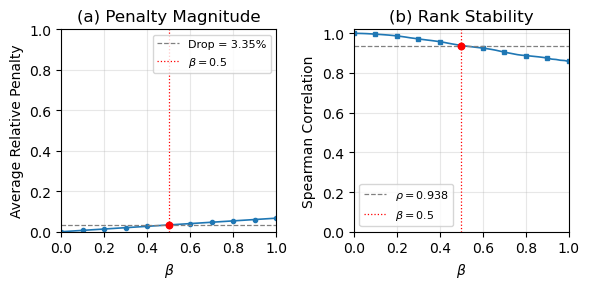

In [12]:
fig_all = plot_beta(
    beta_all,
    selected_stats=selected_beta_summary.loc[
        selected_beta_summary["cohort"].eq("all_eligible")
    ].iloc[0],
    save_path=ASSET_DIR / "beta.pdf",
)


### 9. Output Figure 2: affected citations only

Plot the same metrics using only U<1 to isolate citations changed by author correction. Save `assets/beta-extract.pdf`. Selected-beta annotations come from the affected-subset row of Step 7, so this figure reports its own measured values rather than the all-pairs values. If this subset is empty, skip the figure without replacing it with a fabricated curve; any pre-existing PDF remains unchanged.


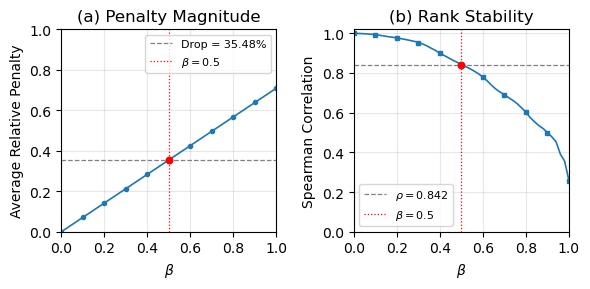

In [13]:
if int(cohort["U"].lt(1).sum()):
    fig_affected = plot_beta(
        beta_affected,
        selected_stats=selected_beta_summary.loc[
            selected_beta_summary["cohort"].eq("U_below_1")
        ].iloc[0],
        save_path=ASSET_DIR / "beta-extract.pdf",
    )
else:
    print("No U < 1 pairs: the affected-only figure was not generated; any existing PDF is unchanged.")


### 10. Save aggregate tables and reproducibility metadata

With `SAVE_RESULTS=True`, save `coverage.csv`, `independence_distribution.csv`, `beta_sensitivity.csv`, and `metadata.json` under `sample/author_independence/`. Metadata records the query time, input/code hashes, parameters, filters, and the selected-beta statistics used for figure annotations. This cell exports aggregate results only: no citation IDs, author names, article text, or database credentials. Repeat runs replace the same derived files; survey and seed inputs are unchanged. Figure PDFs are saved separately by their own cells.


In [14]:
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    coverage.to_csv(OUTPUT_DIR / "coverage.csv", index=False)
    u_distribution.to_csv(OUTPUT_DIR / "independence_distribution.csv", index=False)
    beta_results.to_csv(OUTPUT_DIR / "beta_sensitivity.csv", index=False)
    metadata = {
        "database_query_utc": database_query_utc,
        "seed_input": "sample/seed_papers_final.xlsx",
        "seed_sha256": hashlib.sha256(SEED_FILE.read_bytes()).hexdigest(),
        "notebook_sha256": hashlib.sha256(
            (SRC_DIR / "author_independence.ipynb").read_bytes()
        ).hexdigest(),
        "seed_count": len(seed_ids),
        "citation_pair_count": len(cohort),
        "alpha": ALPHA, "context_discount_final": CONTEXT_DISCOUNT,
        "context_only": CONTEXT_ONLY, "selected_beta": SELECTED_BETA,
        "beta_grid": BETAS.tolist(), "base_random_seed": RANDOM_STATE,
        "plot_annotation_source": "selected_beta_summary generated in Step 7",
        "plot_selected_beta_statistics": selected_beta_summary.to_dict(orient="records"),
        "plot_annotation_role": "Measured values at selected beta, not acceptance thresholds",
        "query_scope": "All stored citation pairs to the fixed 400 cited seed papers",
        "filters": "Cited abstract; context first, citing abstract fallback only "
                   "without context; valid active scores; nonempty author lists "
                   "with valid IDs, names, unique contiguous 0/1-based order "
                   "on both papers; recorded U in [0,1].",
        "author_policy": "Read stored U; exclude missing/invalid U; no U=1 default. "
                         "No new author-graph or historical-date verification.",
        "self_citation_policy": "All recorded U levels retained for beta sensitivity.",
        "baseline": "(alpha*cross+(1-alpha)*LLM)*context_weight",
        "adjusted": "baseline*((1-beta)+beta*U)",
        "relative_drop": "Mean beta*(1-U) for positive baselines only",
        "spearman": "Pearson correlation of average ranks on all retained pairs; "
                    "undefined for fewer than 2 pairs or constant scores",
        "interpretation": "Descriptive sensitivity, not accuracy or optimal-beta validation",
        "outputs": ["coverage.csv", "independence_distribution.csv",
                    "beta_sensitivity.csv", "metadata.json",
                    "../../assets/beta.pdf", "../../assets/beta-extract.pdf"],
    }
    with (OUTPUT_DIR / "metadata.json").open("w", encoding="utf-8") as stream:
        json.dump(metadata, stream, indent=2, allow_nan=False)
    print("Saved aggregate statistics and metadata; no record-level database export.")
else:
    print("Aggregate-file output is disabled (SAVE_RESULTS=False).")


Saved aggregate statistics and metadata; no record-level database export.
